In [4]:
words=open("names.txt", "r").read().splitlines()

In [5]:
len(words)

32033

In [6]:
print((words[:10]))

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [7]:
words[:20]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn',
 'abigail',
 'emily',
 'elizabeth',
 'mila',
 'ella',
 'avery',
 'sofia',
 'camila',
 'aria',
 'scarlett']

In [8]:
# THe shortest and longest words
min(len(w) for w in words)


2

In [9]:
max(len(w) for w in words)

15

In [15]:
# BUilding a a bI GRAM
# WORKING WITH 2 CHARACTERS AT A TIME
# why do we need a <S> and <E>
b={}
for w in words[:1]:
    chs=['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        print(ch1, ch2)

<S> e
e m
m m
m a
a <E>


In [16]:
#how often our characters preve-next appear in teh trainig corpox:

# BUilding a a bI GRAM
# WORKING WITH 2 CHARACTERS AT A TIME
b={}
for w in words[:3]:
    chs=['<S>'] + list(w) + ['<E>']

    
    
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram=(ch1, ch2)
        # print(bigram)
        b[bigram]=b.get(bigram, 0) + 1
        # print(ch1, ch2)
b        

{('<S>', 'e'): 1,
 ('e', 'm'): 1,
 ('m', 'm'): 1,
 ('m', 'a'): 1,
 ('a', '<E>'): 3,
 ('<S>', 'o'): 1,
 ('o', 'l'): 1,
 ('l', 'i'): 1,
 ('i', 'v'): 1,
 ('v', 'i'): 1,
 ('i', 'a'): 1,
 ('<S>', 'a'): 1,
 ('a', 'v'): 1,
 ('v', 'a'): 1}

In [8]:
b

{}

In [28]:
w[1:]

'mma'

In [15]:
w[0]

'a'

In [ ]:
#how often our characters preve-next appear in teh trainig corpox:

# BUilding a a bI GRAM
# WORKING WITH 2 CHARACTERS AT A TIME
b={}
for w in words:
    chs=['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram=(ch1, ch2)
        # print(bigram)
        b[bigram]=b.get(bigram, 0) + 1
        # print(ch1, ch2)
b.items()       

In [ ]:
# sort by count

sorted(b.items(), key=lambda kv: kv[1])
# otehr way around

# sorted(b.items(), key=lambda kv: -kv[1])


In [ ]:
# storing this info in a 2d array, instead of python dictionary

# rows are the first chars of the bigram, and the columsn are going to be the second characters of teh bigram

In [15]:
import torch
torch.zeros((4, 5))

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

In [17]:
joinEverything=''.join(words)


In [19]:
removeDuplicates=set(joinEverything)

In [24]:
# convert to a list
charList=list(removeDuplicates)

In [ ]:
#sort in ascending order
sortedList=sorted(charList)
sortedList

In [ ]:
# build a string to lsit dictionary
stoi={s:i for i, s in enumerate(sortedList)}
stoi

In [36]:
# set <S>=26 and <E>=27
stoi['<S>']=26
stoi['<E>']=27

In [ ]:
N=torch.zeros((28, 28), dtype=torch.int32)
N

In [39]:
for w in words:
    chs=['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1=stoi[ch1]
        ix2=stoi[ch2]
        N[ix1, ix2]+=1 

In [ ]:
N

In [41]:
# better wasy to visualize our table using matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

In [45]:
# integer to string (itos)
itos={i:s for s, i in stoi.items()}
itos

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

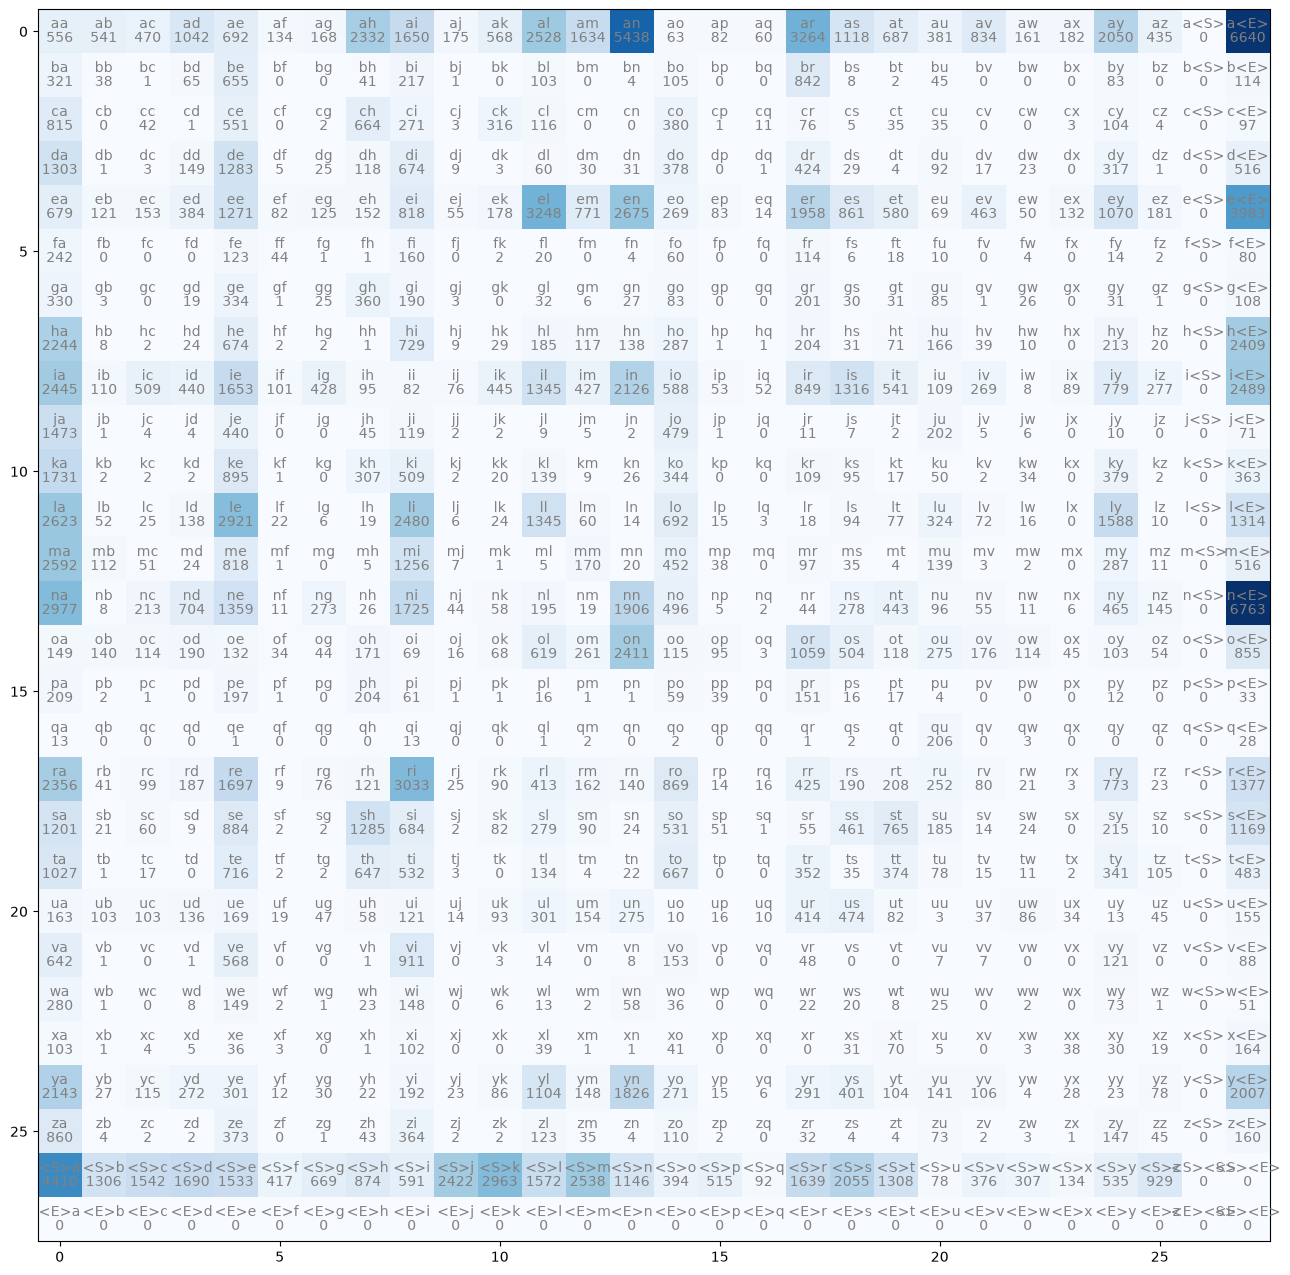

In [47]:
plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')

for i in range(28):
    for j in range(28):
        chstr=itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, N[i, j].item(), ha='center', va='top', color='gray')
plt.axis('on')

In [2]:
#  <E> will never follow <E> same with <S> : so <E><E>=0 same with <S><S>=0

In [ ]:
# but <S><E> can be no zero , if we have a word that has no leters